# Reading relationality off a neuron → `relationality_examples.pdf`

The example neurons of [`../figure_4/figure_example_neurons.ipynb`](../figure_4/figure_example_neurons.ipynb),
one per column, read from that notebook's `UNITS` list (its uncommented entries, in order). Their relationality is the value
[`../figure_4/figure_relationality.ipynb`](../figure_4/figure_relationality.ipynb) marks on its
histogram.

| row | what it shows |
|---|---|
| 1 | measured tuning, objects 90° apart: `tuning_plots`' ring row |
| 2 | measured tuning, objects 180° apart |
| 3 | goodness of fit against relationality: the relational-bias model refit with `bias` held at each value (ΔLL per trial above a constant rate, on all trials). The star is the free fit, labelled with the neuron's inferred relationality |
| 4 | the same 90° chords, coloured by the fitted model's prediction |
| 5 | the same 180° chords, likewise |

Rows 1–2 and 4–5 draw the same chords: the model is evaluated at the data rings' own prototype
pairs, and each ring is rotated by the unit's `rotation_deg` from `figure_example_neurons`. Colour is
per unit and per pair of rows: the two data rings share one scale and the two model rings
share another, as in `tuning_plots`.

At 180° apart the pair's midpoint is fixation, so the model's reference point does not move,
and rows 2 and 5 carry no information about relationality (`relationality_lib`'s "Where it is
blind"). They show what the fitted receptive field does at that separation.


In [4]:
import numpy as np
import matplotlib.pyplot as plt

import common
common.set_style()
import profile_lib as prl
import tuning_lib          # figure 4's ring rows and drawer (importable once profile_lib has run)

OUTPUT = 'relationality_examples.pdf'

BIAS_GRID = np.linspace(0.0, 1.0, 101)   # profile resolution (~0.1 s per value per unit; cached)

# ── Layout, in inches ────────────────────────────────────────────────────────
COL_WIDTH_IN = 1.25        # column pitch
RING_SIZE_IN = 1.05        # ring rows' height
PROFILE_HEIGHT_IN = 1.0    # the goodness-of-fit row's height
MARGINS_IN = (0.95, 0.1, 0.35, 0.45)   # left, right, top, bottom
HSPACE_IN = 0.12           # between rows ...
PROFILE_PAD_ABOVE_IN = 0.2   # ... plus this much more above the profile row (the star's label)
PROFILE_PAD_BELOW_IN = 0.6   # ... and below it (its tick labels and x label)
WSPACE_IN = 0.3            # between the profile panels (their y tick labels)

# ── Marks ────────────────────────────────────────────────────────────────────
PROFILE_COLOR = '0.25'
STAR_COLOR = 'tab:red'
STAR_SIZE = 140
LABEL_FMT = '{:.2f}'       # the inferred relationality, written beside the star


In [5]:
units = prl.example_units()
rows, fits, profiles = [], [], []
for s, ses, u, deg in units:
    r = tuning_lib.unit_rows(s, ses, u, orientation_deg=deg)
    rows.append({90: r[1], 180: r[2]})
    p, dll_hat = prl.free_fit(s, ses, u)
    fits.append((p, dll_hat))
    profiles.append(prl.profile(s, ses, u, BIAS_GRID))
    prof = profiles[-1]
    i = int(prof['dll'].idxmax())
    print(f'Unit {u}: inferred relationality {p["bias"]:.3f} (ΔLL {dll_hat:.4f} nats/trial); '
          f'profile peaks at {prof["bias"][i]:.2f} (ΔLL {prof["dll"][i]:.4f})')


Perle 2022-06-16: 743 2-obj + 205 1-obj trials | unit 89 @ vprobe1/mua (968 trials with spikes) | prototypes at 38°
Unit 89: inferred relationality 0.068 (ΔLL 2.8853 nats/trial); profile peaks at 0.07 (ΔLL 2.8853)
Perle 2022-06-09: 1110 2-obj + 268 1-obj trials | unit 78 @ vprobe1/good (403 trials with spikes) | prototypes at 129°
Unit 78: inferred relationality 0.308 (ΔLL 4.7332 nats/trial); profile peaks at 0.31 (ΔLL 4.7332)
Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 129 @ s0/good (1170 trials with spikes) | prototypes at 9°
Unit 129: inferred relationality 0.557 (ΔLL 0.4643 nats/trial); profile peaks at 0.56 (ΔLL 0.4643)
Perle 2022-06-10: 962 2-obj + 198 1-obj trials | unit 158 @ s0/good (1206 trials with spikes) | prototypes at 170°
Unit 158: inferred relationality 0.738 (ΔLL 3.1669 nats/trial); profile peaks at 0.74 (ΔLL 3.1669)
Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 126 @ s0/good (1170 trials with spikes) | prototypes at 169°
Unit 126: inferred relationa

saved relationality_examples.pdf


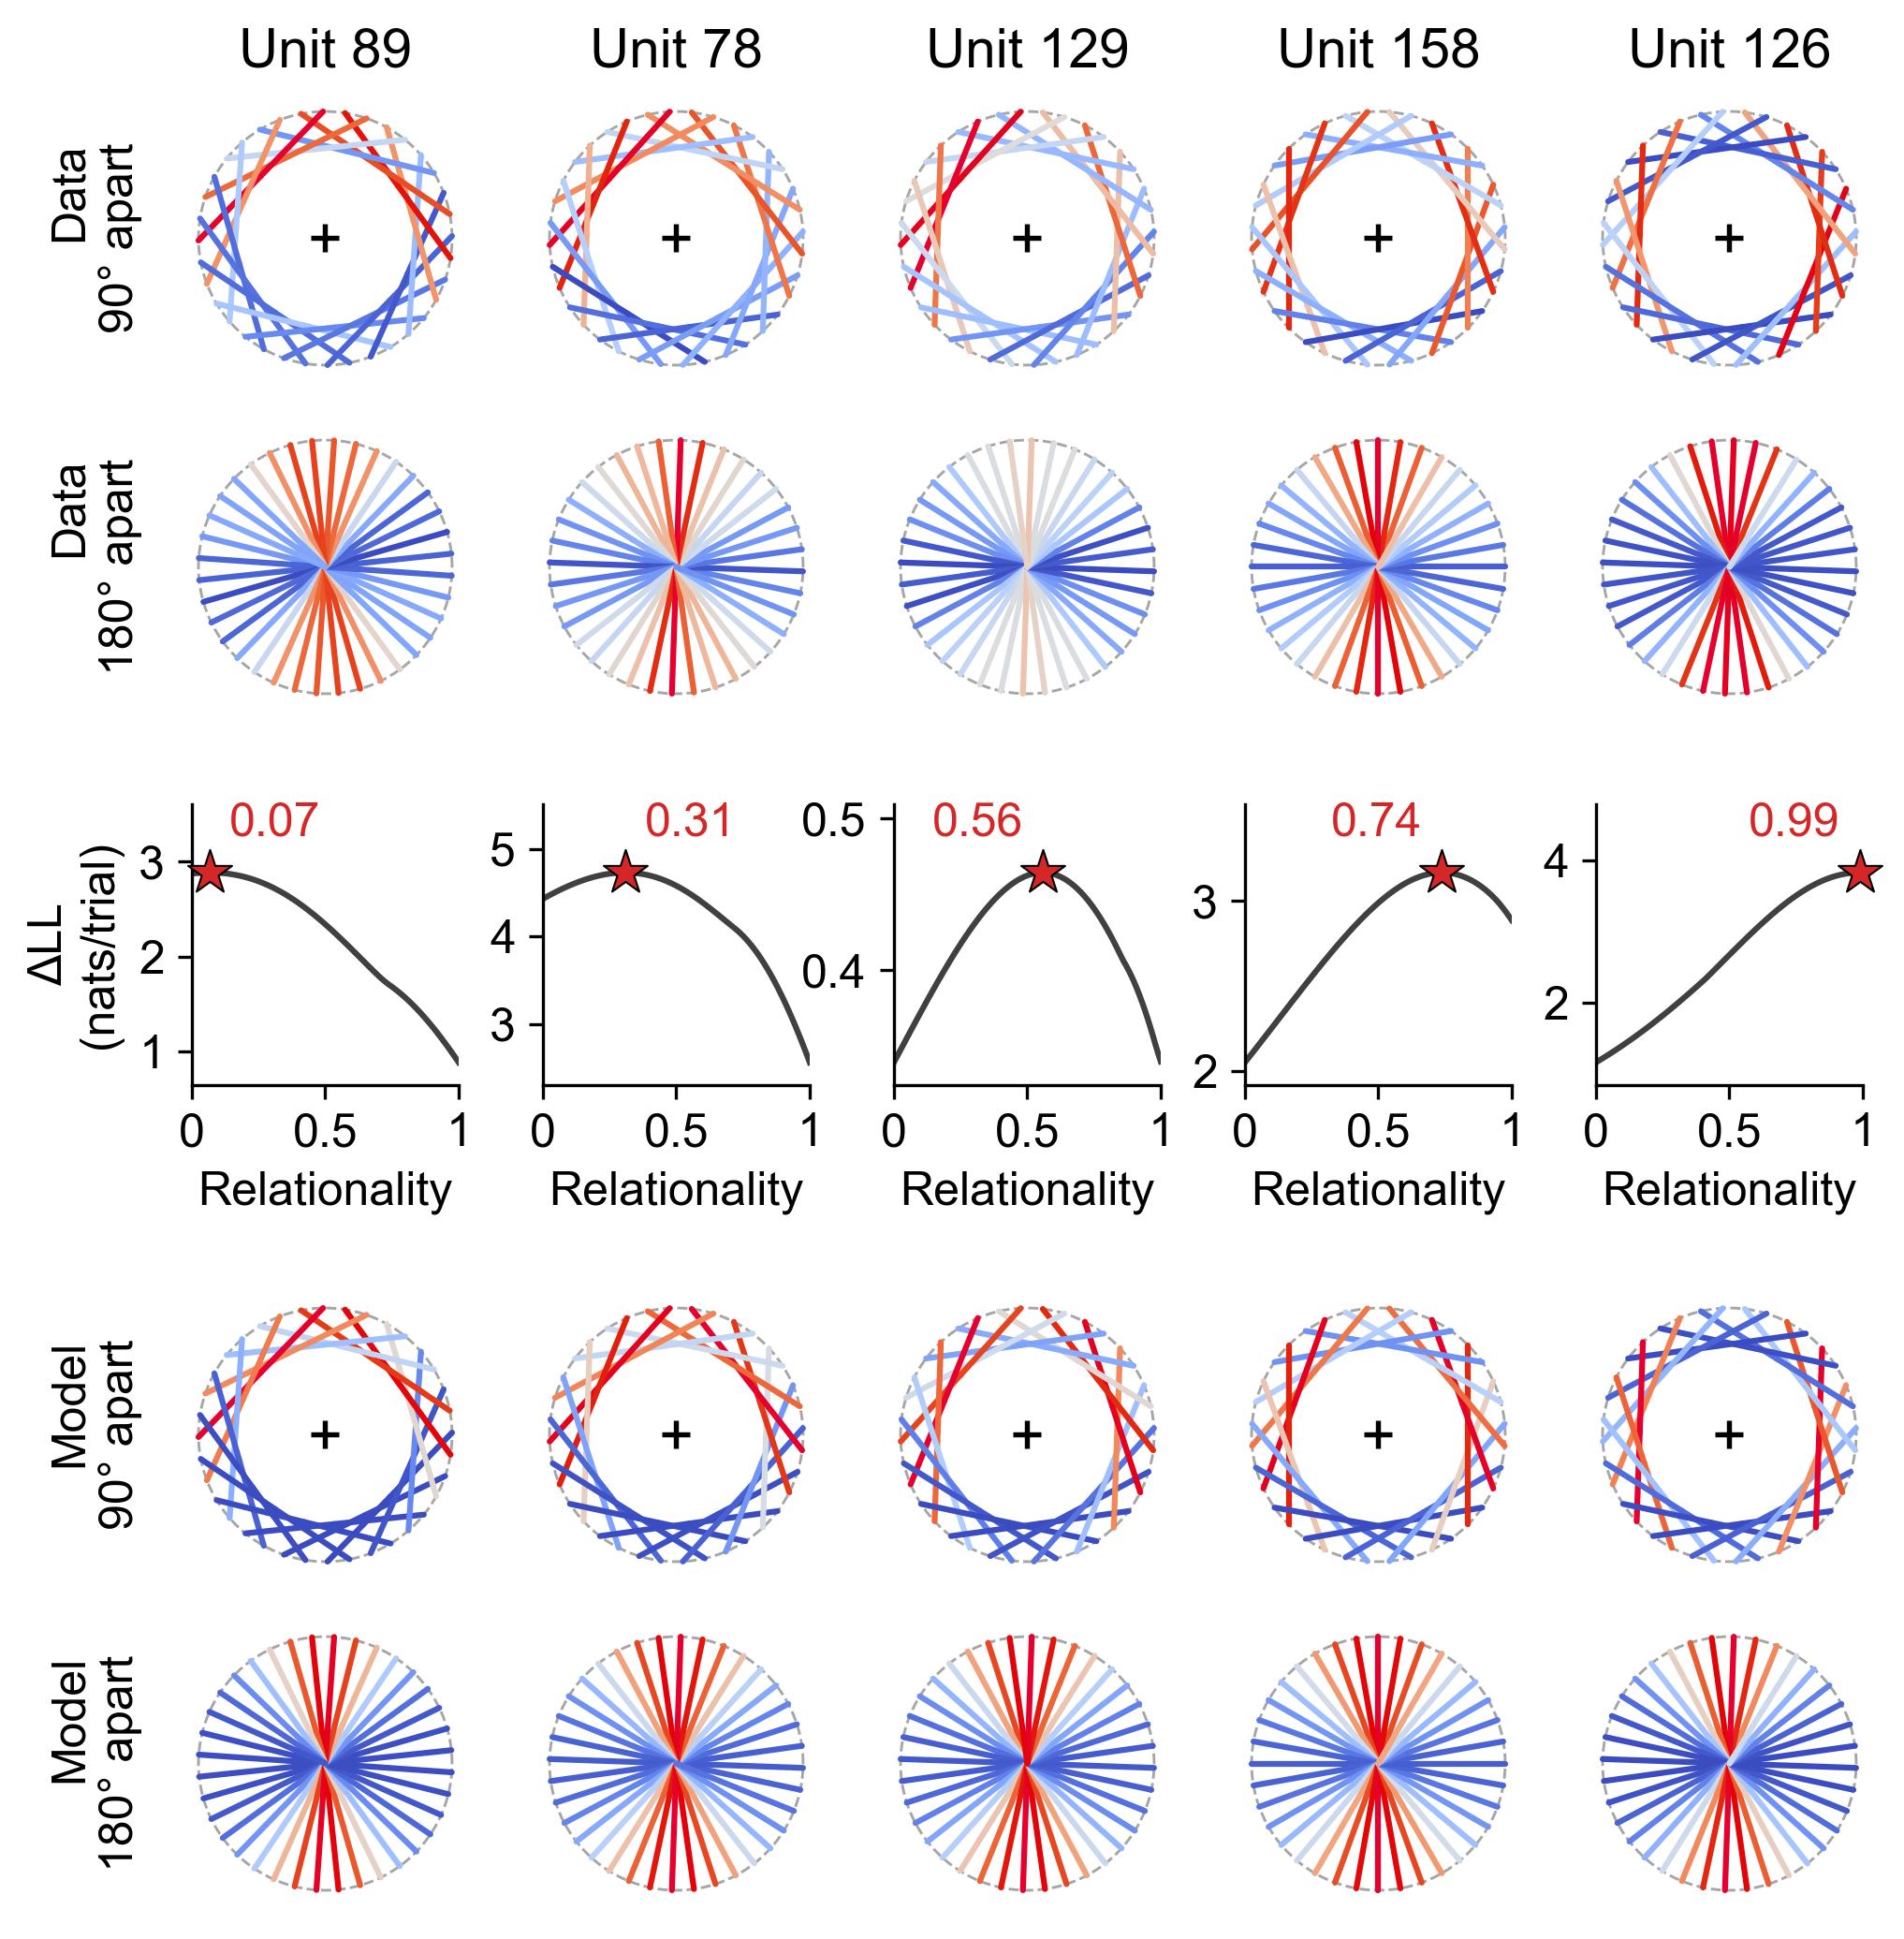

In [6]:
from matplotlib.colors import Normalize

n_cols = len(units)
heights = [RING_SIZE_IN, RING_SIZE_IN, PROFILE_HEIGHT_IN, RING_SIZE_IN, RING_SIZE_IN]
gaps = [HSPACE_IN, HSPACE_IN + PROFILE_PAD_ABOVE_IN, HSPACE_IN + PROFILE_PAD_BELOW_IN, HSPACE_IN]
W = MARGINS_IN[0] + n_cols * COL_WIDTH_IN + MARGINS_IN[1]
H = MARGINS_IN[2] + sum(heights) + sum(gaps) + MARGINS_IN[3]
fig = plt.figure(figsize=(W, H))

def add_ax(r, c, square):
    # Row r, column c, placed in inches so ring sizes and gaps never depend on the figure size.
    top = H - MARGINS_IN[2] - sum(heights[:r]) - sum(gaps[:r])
    h = heights[r]
    x0 = MARGINS_IN[0] + c * COL_WIDTH_IN
    w = RING_SIZE_IN if square else COL_WIDTH_IN - WSPACE_IN
    x = x0 + (COL_WIDTH_IN - w) / 2 if square else x0 + WSPACE_IN / 2
    return fig.add_axes([x / W, (top - h) / H, w / W, h / H])

ROW_LABELS = {0: 'Data\n90° apart', 1: 'Data\n180° apart',
              3: 'Model\n90° apart', 4: 'Model\n180° apart'}
for c, ((s, ses, u, deg), data_rows, (p, dll_hat), prof) in enumerate(
        zip(units, rows, fits, profiles)):
    # Model rings: the data rings' own chords, coloured by the fitted model, on one scale
    # shared by the unit's two model rows.
    model_rows = {sep: dict(data_rows[sep], frs=prl.predicted_rates(p, data_rows[sep]['phis'], sep))
                  for sep in (90, 180)}
    allm = np.concatenate([model_rows[k]['frs'] for k in (90, 180)])
    mnorm = Normalize(vmin=float(allm.min()), vmax=float(allm.max()))
    for k in model_rows:
        model_rows[k]['norm'] = mnorm

    for r, row in ((0, data_rows[90]), (1, data_rows[180]), (3, model_rows[90]),
                   (4, model_rows[180])):
        ax = add_ax(r, c, square=True)
        tuning_lib.draw_tuning_panel(ax, row, cmap=tuning_lib.FIRING_RATE_CMAP, rotate_deg=deg)
        if r == 0:
            ax.set_title(f'Unit {u}')
        if c == 0:
            ax.text(-0.12, 0.5, ROW_LABELS[r], transform=ax.transAxes, rotation=90,
                    ha='right', va='center', fontsize=12)

    ax = add_ax(2, c, square=False)
    ax.plot(prof['bias'], prof['dll'], color=PROFILE_COLOR, lw=1.5, zorder=2)
    b_hat = float(p['bias'])
    ax.scatter([b_hat], [dll_hat], marker='*', s=STAR_SIZE, color=STAR_COLOR,
               edgecolors='k', linewidths=0.5, zorder=3, clip_on=False)
    lo, hi = float(prof['dll'].min()), float(dll_hat)
    pad = 0.12 * (hi - lo if hi > lo else 1.0)
    ax.set_ylim(lo - pad, hi + 3 * pad)              # headroom for the label
    ax.annotate(LABEL_FMT.format(b_hat), (b_hat, dll_hat), xytext=(5 if b_hat < 0.5 else -5, 7),
                textcoords='offset points', ha='left' if b_hat < 0.5 else 'right',
                va='bottom', fontsize=12, color=STAR_COLOR)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.set_xticklabels(['0', '0.5', '1'])
    ax.set_xlabel('Relationality')
    ax.locator_params(axis='y', nbins=3)
    if c == 0:
        ax.set_ylabel('ΔLL\n(nats/trial)')
    common.despine(ax)

common.save(fig, OUTPUT)
plt.show()
